# 02 · Análisis exploratorio de datos (EDA)
**Proyecto final — Machine Learning 1 · FIUNA · 2026**  
**Tema:** Roya asiática de la soja y variables meteorológicas

**Objetivo:** conocer las muestras disponibles para el entrenamiento, su distribución, calidad y relaciones entre variables antes de entrenar modelos.

Trabajamos **solo con el conjunto de desarrollo (entrenamiento histórico)** de las particiones oficiales, sin usar las filas de validación, purga o evaluación final. Esto evita usar información reservada para la evaluación al explorar los datos. El notebook **no entrena modelos ni modifica archivos**.

## 1. Librerías y configuración
Usamos `pandas` para tablas, `numpy` para operaciones numéricas y `matplotlib` para gráficos. Las diez variables meteorológicas y las rutas se toman del procesamiento oficial del proyecto.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Ejecutar desde la raíz del repositorio o desde notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "proyecto.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Abrí el notebook desde la carpeta del proyecto.")
sys.path.insert(0, str(ROOT / "scripts"))
from procesar_datos import FEATURES

DATOS = ROOT / "data" / "processed"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False})

variables = {
    "hr_media_pct": "Humedad media (%)",
    "hr_min_pct": "Humedad mínima (%)",
    "hr_max_pct": "Humedad máxima (%)",
    "temperatura_media_c": "Temperatura media (°C)",
    "temperatura_min_c": "Temperatura mínima (°C)",
    "temperatura_max_c": "Temperatura máxima (°C)",
    "precipitacion_mm": "Precipitación acumulada (mm)",
    "viento_vel_media_10m_ms": "Velocidad del viento (m/s)",
    "viento_u_media_10m_ms": "Viento componente u (m/s)",
    "viento_v_media_10m_ms": "Viento componente v (m/s)",
}
assert set(variables) == set(FEATURES), "Revisar nombres de predictores del proyecto."
print("Datos encontrados:", DATOS)

Datos encontrados: /mnt/data/ml1_review/ml1-proyecto-final-main/data/processed


## 2. Carga y selección de datos
Los archivos de muestras contienen distintos horizontes: **h0** (estado en la fecha de referencia) y **h7** (estado a siete días), con ventanas meteorológicas de **7 y 14 días**.

Para el EDA usamos únicamente los identificadores `train_ids` definidos en `particiones.json`. Cada horizonte y ventana se analiza por separado para **no contar dos veces las mismas etiquetas**.

In [2]:
with open(DATOS / "particiones.json", encoding="utf-8") as archivo:
    particiones = json.load(archivo)

conjuntos = {}
for horizonte in [0, 7]:
    division = particiones[str(horizonte)]["historico"]
    ids_train = division["train_ids"]
    ids_excluidos = set(division["validation_ids"] + division["purged_ids"])
    assert not ids_excluidos.intersection(ids_train)

    for ventana in [7, 14]:
        ruta = DATOS / f"muestras_h{horizonte}_{ventana}d.csv"
        datos = pd.read_csv(ruta).set_index("muestra_id", drop=False)
        assert len(datos.index) == datos.index.nunique()
        assert set(ids_train).issubset(datos.index)
        muestra = datos.loc[ids_train].copy()
        assert (pd.to_datetime(muestra["fecha_objetivo"]) < "2026-01-01").all()
        conjuntos[(horizonte, ventana)] = muestra

    assert conjuntos[(horizonte, 7)].index.equals(conjuntos[(horizonte, 14)].index)
    assert conjuntos[(horizonte, 7)]["y"].equals(conjuntos[(horizonte, 14)]["y"])

resumen = []
for (h, v), datos in conjuntos.items():
    resumen.append({"Horizonte": f"h{h}", "Ventana": f"{v} días",
                    "Muestras": len(datos), "Negativas": (datos.y == 0).sum(),
                    "Positivas": (datos.y == 1).sum(),
                    "Ubicaciones": datos.ubicacion_id.nunique(),
                    "Primera fecha": datos.fecha_objetivo.min(),
                    "Última fecha": datos.fecha_objetivo.max()})
display(pd.DataFrame(resumen))

,Horizonte,Ventana,Muestras,Negativas,Positivas,Ubicaciones,Primera fecha,Última fecha
0,h0,7 días,359,188,171,22,2024-09-02,2025-12-15
1,h0,14 días,359,188,171,22,2024-09-02,2025-12-15
2,h7,7 días,313,157,156,22,2024-09-09,2025-12-15
3,h7,14 días,313,157,156,22,2024-09-09,2025-12-15


**Interpretación:** las ventanas de 7 y 14 días representan las mismas observaciones objetivo dentro de cada horizonte; solo cambian los resúmenes meteorológicos. Por eso el tamaño de la muestra no se duplica al comparar ventanas.

## 3. Calidad y descripción de las variables
Revisamos tipos de datos, estadísticas descriptivas, valores faltantes y números no finitos. Los datos ya pasaron por la preparación del notebook 01: este control se refiere a las **muestras incluidas**, no a la calidad de todos los registros originales.

In [3]:
# Elegimos h0 y 7 días como ejemplo para inspeccionar la estructura.
ejemplo = conjuntos[(0, 7)]
print("Dimensiones:", ejemplo.shape)
display(ejemplo[FEATURES + ["y"]].head())
print("Tipos de datos de los predictores:")
print(ejemplo[FEATURES].dtypes.to_string())

faltantes = pd.DataFrame([
    {"Horizonte": f"h{h}", "Ventana": v,
     "Valores faltantes": int(datos[FEATURES].isna().sum().sum()),
     "Valores no finitos": int((~np.isfinite(datos[FEATURES].to_numpy(dtype=float))).sum())}
    for (h, v), datos in conjuntos.items()
])
display(faltantes)

# La tabla estadística completa se calcula para las cuatro combinaciones.
for (h, v), datos in conjuntos.items():
    print(f"Estadísticas de h{h}, ventana de {v} días")
    estadisticas = datos[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]
    display(estadisticas.rename(columns={"mean": "Media", "std": "Desv. estándar",
                                         "min": "Mínimo", "50%": "Mediana", "max": "Máximo"}).round(2))

Dimensiones: (359, 32)


,hr_media_pct,hr_min_pct,hr_max_pct,temperatura_media_c,temperatura_min_c,temperatura_max_c,precipitacion_mm,viento_vel_media_10m_ms,viento_u_media_10m_ms,viento_v_media_10m_ms,y
muestra_id,,,,,,,,,,,
O0daf4b9b85eb403117b7_h0,67.613095,28.0,100.0,13.993452,-1.0,27.3,0.0,3.015655,-0.702679,-1.020719,0
O0e1b125cd6cb2ca171ed_h0,70.023810,32.0,95.0,13.996429,-1.2,27.2,0.0,2.059583,-0.460562,-0.392832,0
O2a0993c5db00626418bb_h0,65.827381,34.0,98.0,15.453571,1.7,28.5,0.0,2.454345,-0.575957,-0.565792,1
O7dfc5bb16574142b2df2_h0,63.351190,34.0,100.0,14.732738,-0.2,27.1,0.0,2.916548,-0.945200,-0.818773,1
O822afaaa2a1be0290f2e_h0,66.309524,26.0,98.0,15.054762,1.3,28.7,0.0,2.090655,-0.110576,-0.541432,0


Tipos de datos de los predictores:
hr_media_pct               float64
hr_min_pct                 float64
hr_max_pct                 float64
temperatura_media_c        float64
temperatura_min_c          float64
temperatura_max_c          float64
precipitacion_mm           float64
viento_vel_media_10m_ms    float64
viento_u_media_10m_ms      float64
viento_v_media_10m_ms      float64


,Horizonte,Ventana,Valores faltantes,Valores no finitos
0,h0,7,0,0
1,h0,14,0,0
2,h7,7,0,0
3,h7,14,0,0


Estadísticas de h0, ventana de 7 días


,Media,Desv. estándar,Mínimo,Mediana,Máximo
hr_media_pct,75.83,6.81,59.18,76.35,91.74
hr_min_pct,39.29,8.12,21.00,39.00,67.00
hr_max_pct,98.30,2.25,88.00,99.00,100.00
temperatura_media_c,19.00,2.57,10.55,19.28,25.22
temperatura_min_c,10.89,3.57,-1.20,11.20,18.80
temperatura_max_c,28.36,2.65,18.10,28.40,33.60
precipitacion_mm,41.72,32.54,0.00,35.90,176.60
viento_vel_media_10m_ms,2.85,0.64,1.59,2.78,5.04
viento_u_media_10m_ms,-0.83,0.86,-3.69,-0.75,1.37
viento_v_media_10m_ms,-0.82,0.72,-3.27,-0.77,1.21


... (2 outputs left out)

Estadísticas de h7, ventana de 7 días


,Media,Desv. estándar,Mínimo,Mediana,Máximo
hr_media_pct,75.46,6.73,59.18,75.76,91.74
hr_min_pct,38.62,8.16,21.00,38.00,67.00
hr_max_pct,98.25,2.28,88.00,99.00,100.00
temperatura_media_c,18.89,2.62,10.55,19.13,25.22
temperatura_min_c,10.64,3.53,-1.20,10.70,18.80
temperatura_max_c,28.41,2.73,18.10,28.50,33.60
precipitacion_mm,38.72,30.20,0.00,33.10,173.60
viento_vel_media_10m_ms,2.83,0.64,1.59,2.77,5.04
viento_u_media_10m_ms,-0.93,0.78,-3.23,-0.83,0.43
viento_v_media_10m_ms,-0.81,0.73,-3.27,-0.76,1.21


Estadísticas de h7, ventana de 14 días


,Media,Desv. estándar,Mínimo,Mediana,Máximo
hr_media_pct,75.54,5.31,63.46,75.46,90.42
hr_min_pct,34.27,6.03,21.00,33.00,56.00
hr_max_pct,99.26,1.18,94.00,100.00,100.00
temperatura_media_c,18.68,2.45,10.12,18.73,24.60
temperatura_min_c,9.08,3.45,-1.20,9.30,18.00
temperatura_max_c,29.35,2.21,20.40,29.60,33.60
precipitacion_mm,76.35,38.10,2.10,76.60,208.60
viento_vel_media_10m_ms,2.87,0.54,1.71,2.82,4.28
viento_u_media_10m_ms,-0.96,0.61,-2.89,-0.95,0.18
viento_v_media_10m_ms,-0.82,0.49,-2.20,-0.80,0.48


**Interpretación:** el análisis de faltantes comprueba si los conjuntos seleccionados contienen valores utilizables por los modelos. Las variables tienen unidades diferentes; el escalado para regresión logística se realizará dentro del pipeline del modelado, no aquí.

## 4. Distribución de la variable objetivo
La variable `y` tiene dos clases: **0 = negativo** y **1 = positivo**. Calculamos su frecuencia una sola vez por horizonte, usando la ventana de siete días.

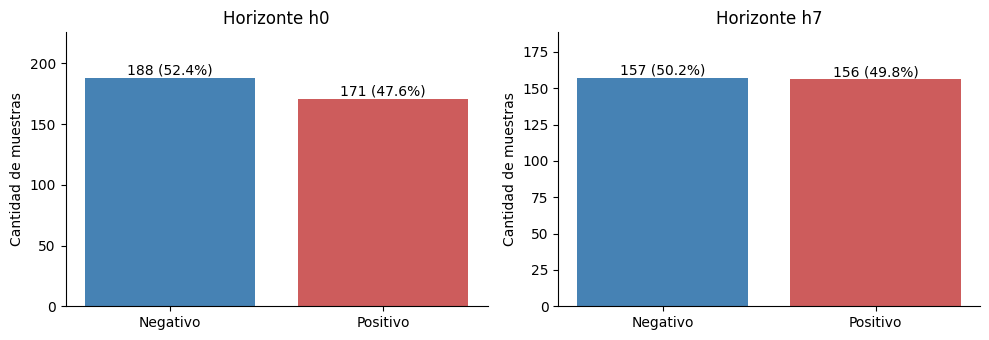

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for h, ax in zip([0, 7], axes):
    cantidades = conjuntos[(h, 7)].y.value_counts().reindex([0, 1], fill_value=0)
    ax.bar(["Negativo", "Positivo"], cantidades, color=["steelblue", "indianred"])
    ax.set(title=f"Horizonte h{h}", ylabel="Cantidad de muestras")
    for x, cantidad in enumerate(cantidades):
        ax.text(x, cantidad, f"{cantidad} ({cantidad / cantidades.sum():.1%})",
                ha="center", va="bottom")
    ax.set_ylim(0, max(cantidades) * 1.2)
plt.tight_layout()
plt.show()

**Interpretación:** el balance de clases puede ser diferente entre h0 y h7 porque el horizonte futuro exige disponer de seguimiento. Los modelos se evaluarán con métricas apropiadas, no solo con accuracy.

## 5. Distribuciones meteorológicas
Para evitar veinte histogramas repetidos, visualizamos **cuatro variables representativas**: humedad media, temperatura media, precipitación y velocidad del viento. Comparamos las ventanas de 7 y 14 días para h0; las tablas descriptivas anteriores incluyen los diez predictores y ambos horizontes.

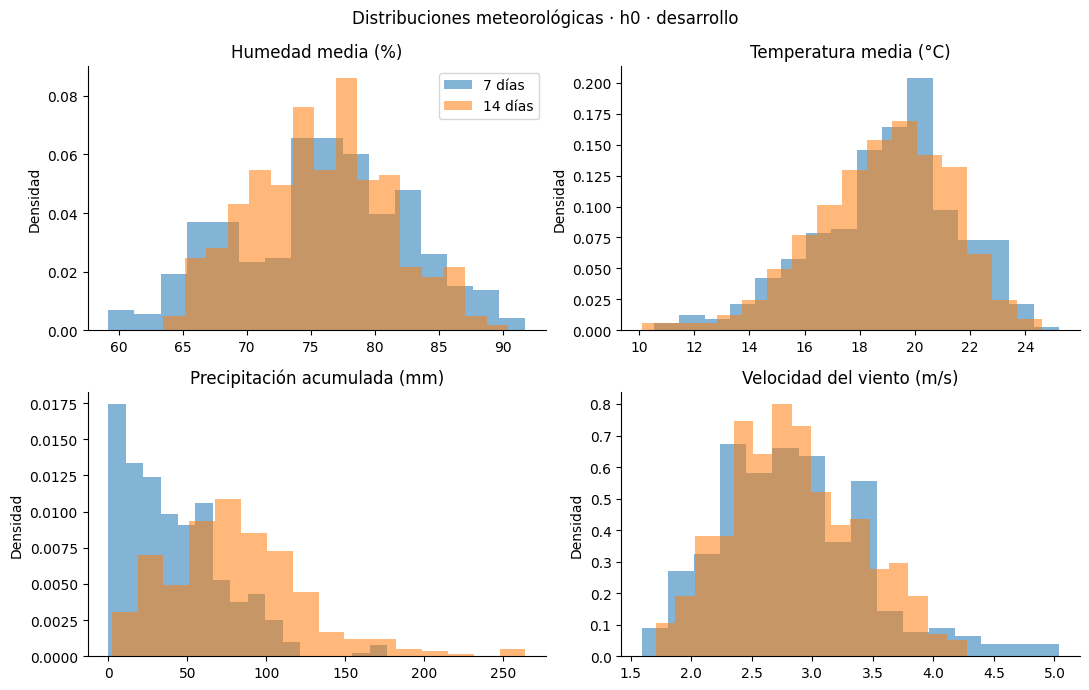

,Horizonte,Ventana,Mediana (mm),Percentil 95 (mm)
0,h0,7 días,35.9,99.11
1,h0,14 días,79.1,159.73
2,h7,7 días,33.1,95.84
3,h7,14 días,76.6,137.10


In [5]:
destacadas = ["hr_media_pct", "temperatura_media_c", "precipitacion_mm",
             "viento_vel_media_10m_ms"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for variable, ax in zip(destacadas, axes.flat):
    for ventana in [7, 14]:
        ax.hist(conjuntos[(0, ventana)][variable], bins=16, alpha=0.55,
                density=True, label=f"{ventana} días")
    ax.set(title=variables[variable], ylabel="Densidad")
axes[0, 0].legend()
fig.suptitle("Distribuciones meteorológicas · h0 · desarrollo")
plt.tight_layout()
plt.show()

lluvia = pd.DataFrame([
    {"Horizonte": f"h{h}", "Ventana": f"{v} días",
     "Mediana (mm)": datos.precipitacion_mm.median(),
     "Percentil 95 (mm)": datos.precipitacion_mm.quantile(.95)}
    for (h, v), datos in conjuntos.items()
])
display(lluvia.round(2))

**Interpretación:** al extender la ventana de 7 a 14 días, algunos resúmenes pueden cambiar por construcción (por ejemplo, la precipitación acumulada). No se puede afirmar que una ventana sea mejor para predecir únicamente por su distribución.

## 6. Comparación de variables por clase
Los boxplots permiten comparar medianas, dispersión y valores extremos entre muestras positivas y negativas. Mostramos las mismas cuatro variables para **h0, ventana de 7 días**, y dejamos las otras combinaciones disponibles en las tablas de arriba.

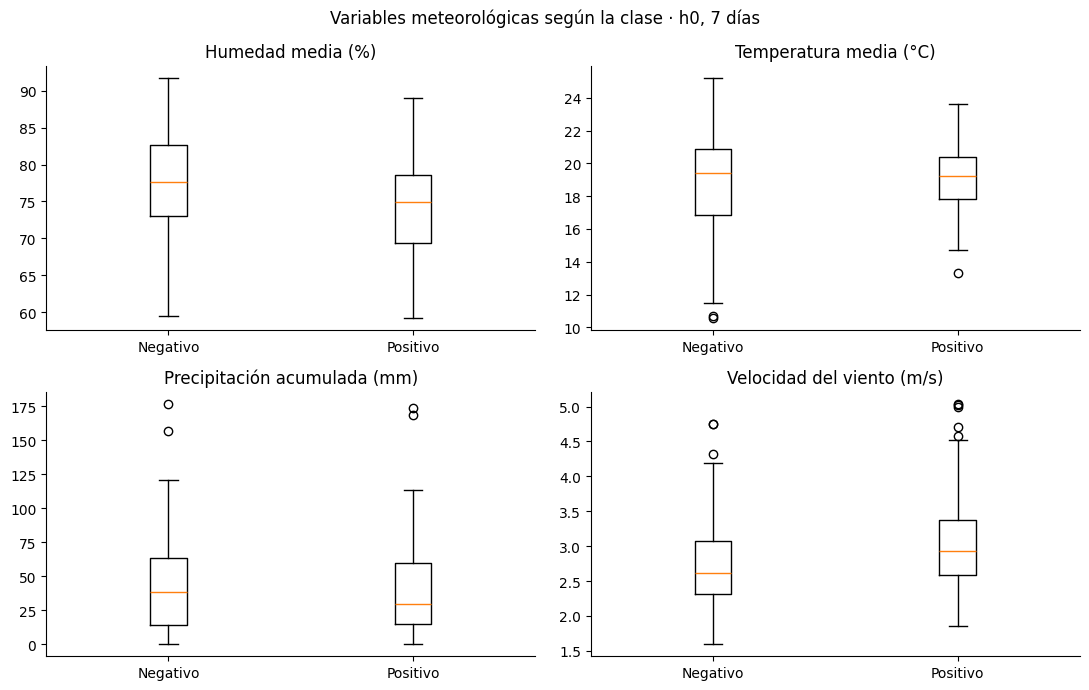

In [6]:
datos = conjuntos[(0, 7)]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for variable, ax in zip(destacadas, axes.flat):
    negativos = datos.loc[datos.y == 0, variable]
    positivos = datos.loc[datos.y == 1, variable]
    ax.boxplot([negativos, positivos], tick_labels=["Negativo", "Positivo"])
    ax.set(title=variables[variable])
fig.suptitle("Variables meteorológicas según la clase · h0, 7 días")
plt.tight_layout()
plt.show()

**Interpretación:** los boxplots describen asociaciones, pero no demuestran relaciones causales. Además, varias observaciones pueden proceder de una misma ubicación y no deben tratarse como totalmente independientes.

## 7. Correlación entre predictores
Calculamos la correlación de Pearson de las diez variables meteorológicas. Para no repetir cuatro matrices casi iguales, mostramos **h0, 7 días** e indicamos que la selección definitiva de predictores pertenece a la validación del modelado.

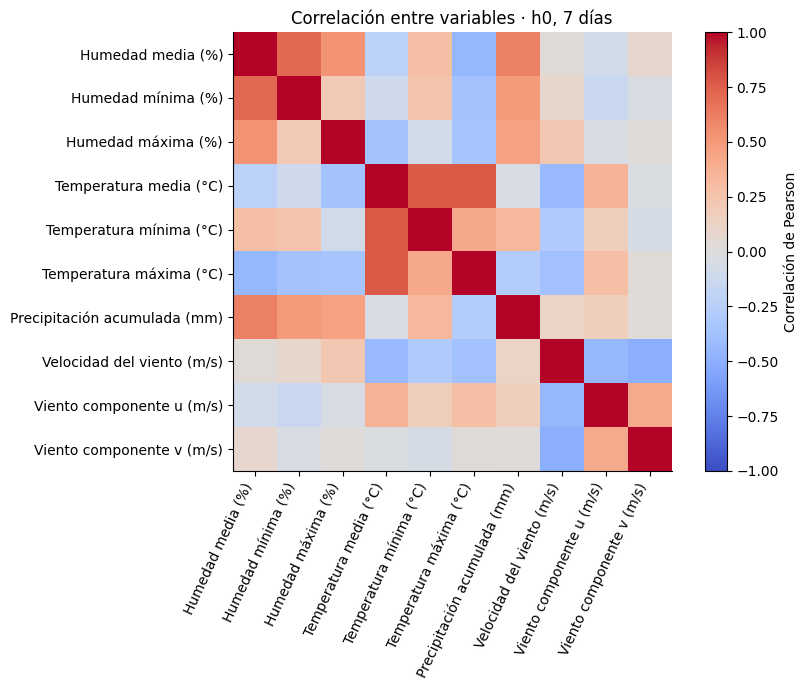

Correlación
temperatura_media_c temperatura_max_c        0.770
                    temperatura_min_c        0.769
hr_media_pct        hr_min_pct               0.713
                    precipitacion_mm         0.613
                    hr_max_pct               0.526

In [7]:
correlacion = conjuntos[(0, 7)][FEATURES].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), [variables[f] for f in FEATURES], rotation=65, ha="right")
ax.set_yticks(range(len(FEATURES)), [variables[f] for f in FEATURES])
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlación entre variables · h0, 7 días")
plt.tight_layout()
plt.show()

# Pares con mayor correlación absoluta (sin incluir la diagonal).
pares = correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1)).stack()
pares_fuertes = pares.reindex(pares.abs().sort_values(ascending=False).index).head(5)
display(pares_fuertes.rename("Correlación").round(3).to_frame())

**Interpretación:** variables de una misma familia (por ejemplo, media, mínimo y máximo de temperatura o humedad) pueden estar correlacionadas. La correlación por sí sola no justifica eliminarlas ni demuestra capacidad predictiva.

## 8. Cobertura temporal y geográfica
La cantidad de monitoreos varía con la fecha y el lugar. Por eso examinamos dónde y cuándo tenemos muestras. Usamos una única ventana por horizonte para no duplicar las observaciones.

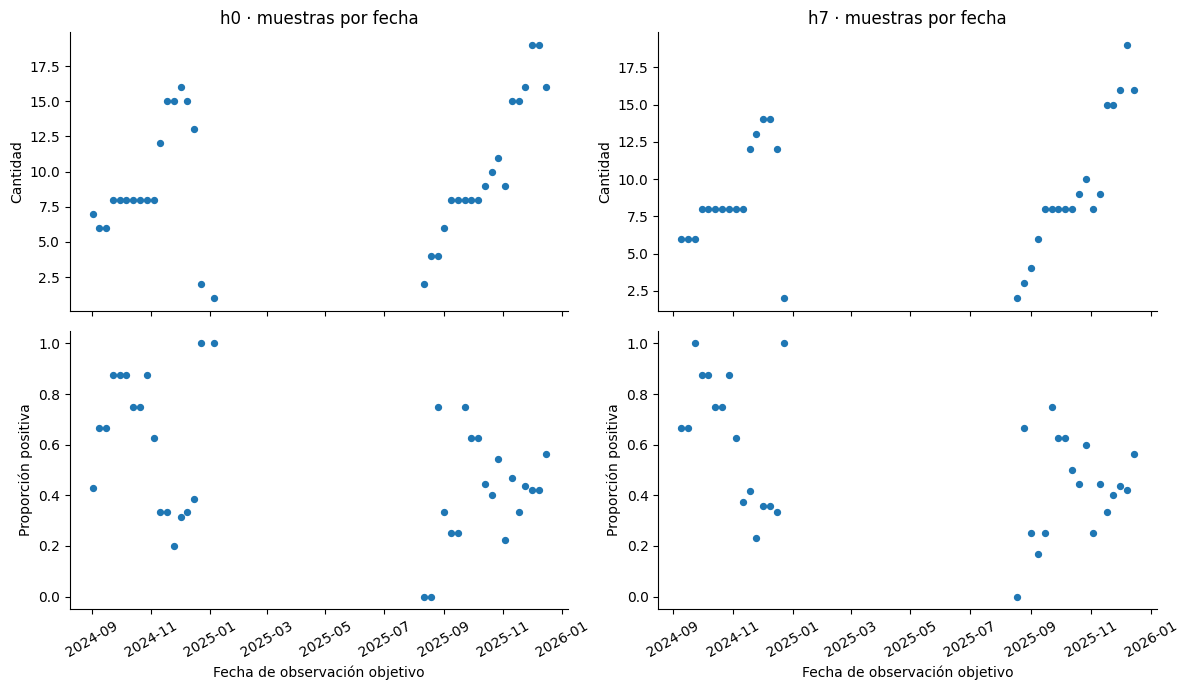

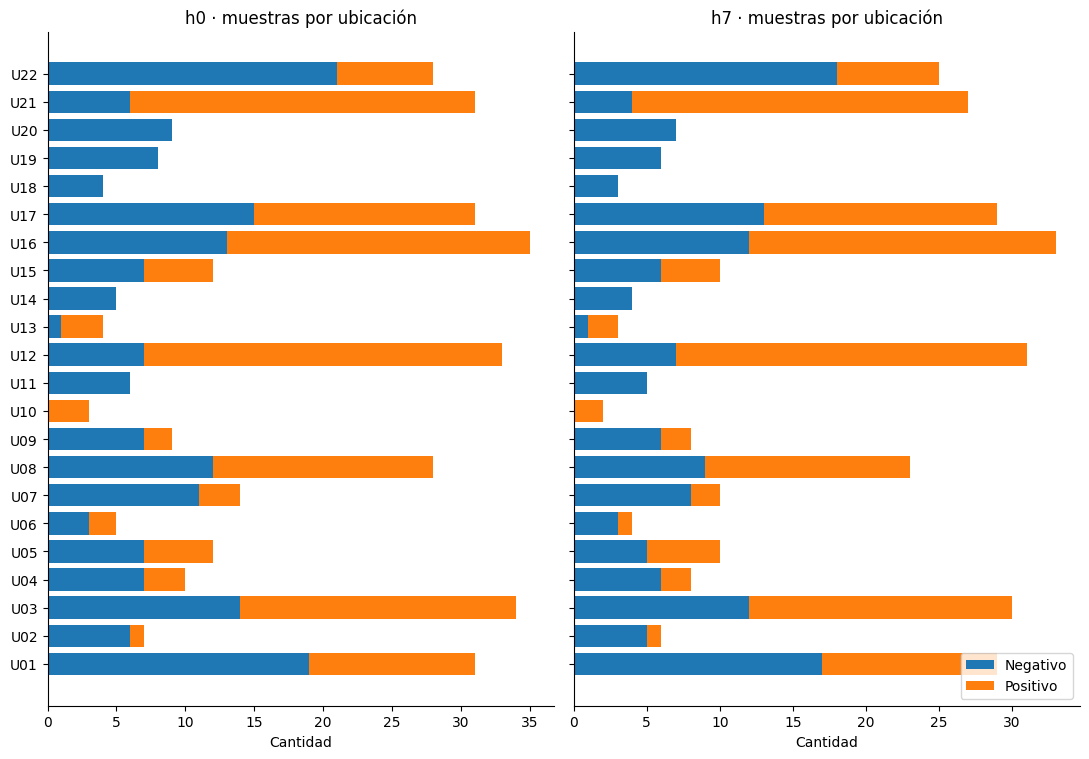

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
for columna, h in enumerate([0, 7]):
    datos = conjuntos[(h, 7)].copy()
    datos["fecha_objetivo"] = pd.to_datetime(datos["fecha_objetivo"])
    por_fecha = datos.groupby("fecha_objetivo").y.agg(n="size", positivos="sum")
    axes[0, columna].scatter(por_fecha.index, por_fecha.n, s=18)
    axes[0, columna].set(title=f"h{h} · muestras por fecha", ylabel="Cantidad")
    axes[1, columna].scatter(por_fecha.index, por_fecha.positivos / por_fecha.n, s=18)
    axes[1, columna].set(ylabel="Proporción positiva", ylim=(-0.05, 1.05),
                          xlabel="Fecha de observación objetivo")
    for ax in axes[:, columna]:
        ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()

# Identificadores anónimos solo para visualización; no son predictores.
ubicaciones = sorted(set(conjuntos[(0, 7)].ubicacion_id) | set(conjuntos[(7, 7)].ubicacion_id))
codigos = {ubicacion: f"U{i:02d}" for i, ubicacion in enumerate(ubicaciones, 1)}
fig, axes = plt.subplots(1, 2, figsize=(11, max(4, len(ubicaciones) * 0.35)), sharey=True)
for ax, h in zip(axes, [0, 7]):
    tabla = conjuntos[(h, 7)].groupby("ubicacion_id").y.agg(n="size", positivos="sum")
    tabla.index = tabla.index.map(codigos)
    tabla = tabla.reindex(codigos.values(), fill_value=0)
    ax.barh(tabla.index, tabla.n - tabla.positivos, label="Negativo")
    ax.barh(tabla.index, tabla.positivos, left=tabla.n - tabla.positivos, label="Positivo")
    ax.set(title=f"h{h} · muestras por ubicación", xlabel="Cantidad")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretación:** existen fechas sin registros y diferencias de cobertura entre ubicaciones. Una fecha sin muestra no equivale a ausencia de roya. La evaluación temporal del proyecto mide el comportamiento en períodos posteriores de ubicaciones previamente observadas; **no equivale** a evaluar localidades completamente nuevas.

## 9. Conclusiones

- Los conjuntos analizados corresponden únicamente al **desarrollo histórico**, separado de validación, purga y evaluación final.
- Los horizontes h0 y h7 tienen cantidades de muestras distintas; las ventanas de 7 y 14 días comparten etiquetas dentro de cada horizonte.
- Los diez predictores meteorológicos se describieron con estadísticas y controles de valores faltantes; sus escalas son diferentes.
- Los gráficos permiten explorar distribución, solapamiento entre clases y correlaciones, **sin probar causalidad**.
- La cobertura temporal y por ubicación es desigual y limita la generalización de las conclusiones.

**Siguiente notebook:** `03_evaluacion.ipynb`, donde se entrenan o reproducen los modelos y se comparan sus resultados usando la validación temporal oficial.